<a href="https://colab.research.google.com/github/Killeryoung/ML/blob/main/%D0%9B%D0%B5%D0%BA%D1%86%D1%96%D1%8F_RNN_%D0%93%D1%83%D1%80%D0%BA%D0%BE_%D0%94%D0%B0%D0%BD%D0%B8%D0%BB%D0%BE_%D0%A4%D0%86%D0%A2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Машинне навчання. Рекурентні нейронні мережі
## Тренувальний ноутбук: RNN, LSTM, GRU
**Мета:** навчитися готувати послідовності слів, використовувати Embedding, навчати рекурентні моделі, аналізувати графіки та генерувати текст.

Середовище: Google Colab, Python, TensorFlow/Keras. Виконуйте клітинки послідовно. Завдання 1–4 містять готові приклади, завдання 5 — для самостійного виконання.

## Завдання 1. Підготовка тексту
Модель прогнозує наступне слово за трьома попередніми. Токенізатор надає кожному слову числовий індекс. Індекс 0 зарезервовано; невідомі слова отримують індекс OOV. Для навчання використовуємо цілочислові мітки, тому one-hot кодування не потрібне.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, GRU, Dense
from tensorflow.keras.preprocessing.text import Tokenizer

tf.keras.utils.set_random_seed(42)

texts = """
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..
Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?.
Не питали б люде, що в мене болить,
Не питали б, за що проклинаю долю,
Чого нуджу світом? «Нічого робить», —
Не сказали б на сміх...
"""
texts = texts.replace('\ufeff', '')
tokenizer = Tokenizer(filters=Tokenizer().filters + '–—«»…', lower=True,
                      oov_token='<OOV>')
tokenizer.fit_on_texts([texts])
res = np.array(tokenizer.texts_to_sequences([texts])[0], dtype=np.int32)
vocab_size = len(tokenizer.word_index) + 1
print('Кількість слів:', len(res))
print('Розмір словника:', vocab_size)
print('Перші індекси:', res[:10])
print('Перші слова словника:', list(tokenizer.word_index.items())[:10])

Кількість слів: 77
Розмір словника: 52
Перші індекси: [ 9 10  9 10  5 15 16 17 18 19]
Перші слова словника: [('<OOV>', 1), ('не', 2), ('на', 3), ('в', 4), ('лихо', 5), ('чом', 6), ('вас', 7), ('б', 8), ('думи', 9), ('мої', 10)]


In [2]:
inp_words = 3
X = np.array([res[i:i+inp_words] for i in range(len(res)-inp_words)])
Y = res[inp_words:]
print('X:', X.shape, 'Y:', Y.shape)
for x, y in zip(X[:5], Y[:5]):
    print(' '.join(tokenizer.index_word[int(i)] for i in x),
          '→', tokenizer.index_word[int(y)])

X: (74, 3) Y: (74,)
думи мої думи → мої
мої думи мої → лихо
думи мої лихо → мені
мої лихо мені → з
лихо мені з → вами


## Завдання 2. Прогнозування слів з Embedding та SimpleRNN
Embedding перетворює індекси слів на вектори. SimpleRNN формує прихований стан розмірності 128. Dense із softmax повертає ймовірності для всього словника. Оскільки Y містить індекси, використовуємо `sparse_categorical_crossentropy` (еквівалент categorical crossentropy з one-hot мітками).

Для цього дуже малого корпусу навчаємо модель на всіх вікнах, щоб продемонструвати запам’ятовування. Accuracy тут є навчальною, а не оцінкою узагальнення.

In [3]:
def make_model(layer_class, window=3, units=128, embedding_dim=256):
    model = Sequential([
        Input(shape=(window,), dtype='int32'),
        Embedding(vocab_size, embedding_dim),
        layer_class(units, activation='tanh'),
        Dense(vocab_size, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model = make_model(SimpleRNN, window=inp_words)
model.summary()
history = model.fit(X, Y, batch_size=32, epochs=50, verbose=0)
print('Останній loss:', history.history['loss'][-1])
print('Остання accuracy:', history.history['accuracy'][-1])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 3, 256)         │        13,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 52)             │         6,708 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,300 (270.70 KB)

 Trainable params: 69,300 (270.70 KB)

 Non-trainable params: 0 (0.00 B)

Останній loss: 0.06661739945411682
Остання accuracy: 0.9864864945411682


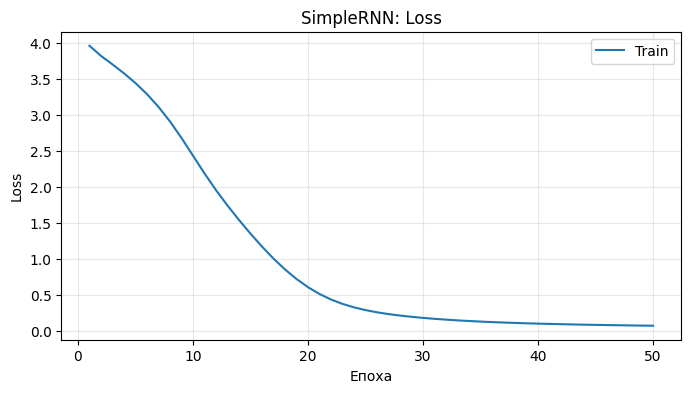

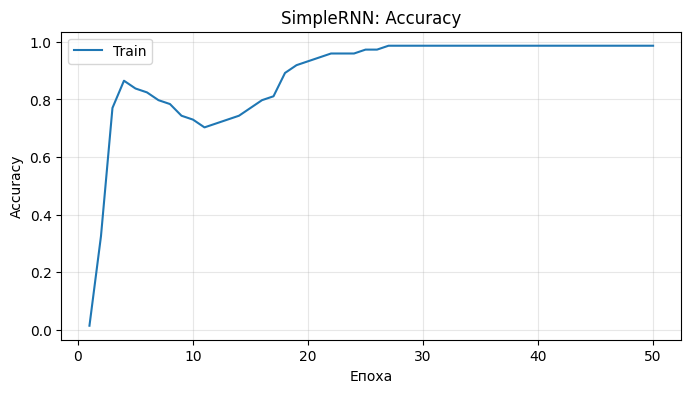

In [4]:
def plot_history(history, name):
    for metric, ylabel in [('loss', 'Loss'), ('accuracy', 'Accuracy')]:
        plt.figure(figsize=(8, 4))
        values = history.history[metric]
        plt.plot(range(1, len(values)+1), values, label='Train')
        if 'val_'+metric in history.history:
            v = history.history['val_'+metric]
            plt.plot(range(1, len(v)+1), v, label='Validation')
        plt.xlabel('Епоха')
        plt.ylabel(ylabel)
        plt.title(f'{name}: {ylabel}')
        plt.grid(alpha=0.3)
        plt.legend()
        plt.show()

plot_history(history, 'SimpleRNN')

## Завдання 3. Генерація тексту
На кожному кроці модель отримує останні три слова, прогнозує наступне, додає його до послідовності та повторює процес. Використовуємо argmax — вибір найімовірнішого слова. Індекси 0 та OOV виключаємо з генерації.

In [5]:
def buildPhrase(text, str_len=20, model=model, window=inp_words):
    data = tokenizer.texts_to_sequences([text])[0]
    if len(data) < window:
        raise ValueError(f'Введіть щонайменше {window} слів')
    result = text.strip()
    for _ in range(str_len):
        inp = np.array([data[-window:]], dtype=np.int32)
        pred = model.predict(inp, verbose=0)[0].copy()
        pred[0] = -1
        pred[tokenizer.word_index[tokenizer.oov_token]] = -1
        indx = int(np.argmax(pred))
        data.append(indx)
        result += ' ' + tokenizer.index_word[indx]
    return result

print(buildPhrase('Думи мої думи'))
print(buildPhrase('Чом вас вітер', str_len=12))

Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину
Чом вас вітер не розвіяв в степу як пилину чом вас лихо не приспало як


**Для обговорення:** чому модель іноді повторює слова? Чому інший початок фрази може давати нелогічний результат?

## Завдання 4. LSTM та GRU. Порівняння моделей
Замінимо рекурентний шар, залишивши однакові розмірності Embedding, прихованого стану, кількість епох і дані. LSTM використовує окремий стан пам’яті та три вентилі; GRU — два вентилі без окремого стану комірки. Кількість параметрів моделей різна.

In [6]:
models = {'SimpleRNN': model}
histories = {'SimpleRNN': history}
for name, layer in [('LSTM', LSTM), ('GRU', GRU)]:
    tf.keras.utils.set_random_seed(42)
    models[name] = make_model(layer, window=inp_words)
    models[name].summary()
    histories[name] = models[name].fit(X, Y, epochs=50, batch_size=32, verbose=0)
    print(name, buildPhrase('Думи мої думи', model=models[name]))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 256)         │        13,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 52)             │         6,708 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 217,140 (848.20 KB)

 Trainable params: 217,140 (848.20 KB)

 Non-trainable params: 0 (0.00 B)

LSTM Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину


... (2 outputs left out)

 Total params: 168,244 (657.20 KB)

 Trainable params: 168,244 (657.20 KB)

 Non-trainable params: 0 (0.00 B)

GRU Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину


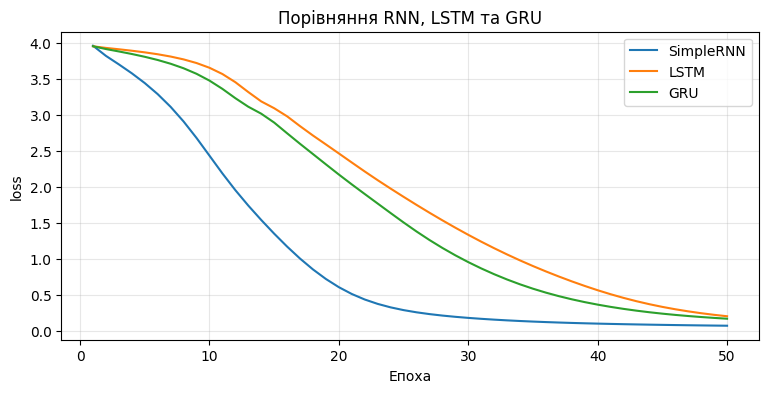

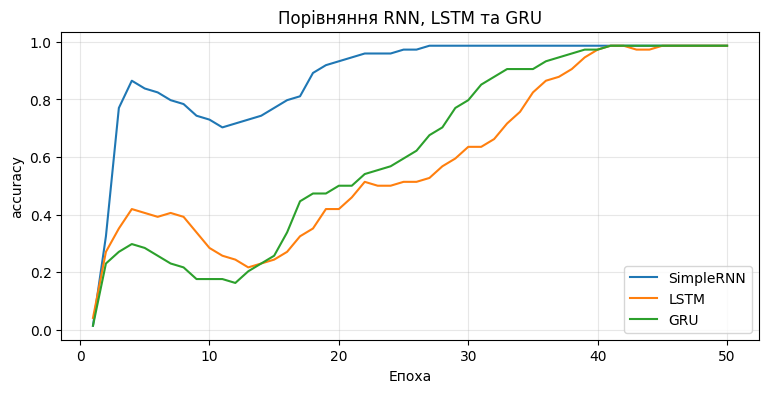

,Модель,Параметри,Train loss,Train accuracy
0,SimpleRNN,69300,0.066617,0.986486
1,LSTM,217140,0.198417,0.986486
2,GRU,168244,0.164280,0.986486


In [7]:
for metric in ['loss', 'accuracy']:
    plt.figure(figsize=(9, 4))
    for name, hist in histories.items():
        values = hist.history[metric]
        plt.plot(range(1, len(values)+1), values, label=name)
    plt.xlabel('Епоха')
    plt.ylabel(metric)
    plt.title('Порівняння RNN, LSTM та GRU')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

import pandas as pd
pd.DataFrame([
    {'Модель': name, 'Параметри': models[name].count_params(),
     'Train loss': h.history['loss'][-1], 'Train accuracy': h.history['accuracy'][-1]}
    for name, h in histories.items()
])

### Аналіз результатів
Порівняйте криві, швидкість зменшення втрат і кількість параметрів. Найвища навчальна accuracy не гарантує найкращої генерації на нових текстах. Для повноцінної перевірки потрібен більший корпус та окрема валідаційна вибірка без перетину текстових фрагментів.

## Завдання 5. Самостійна робота
Оберіть інший український текст (бажано значно довший за наведений приклад). Побудуйте власну модель прогнозування наступного слова. Усі наступні клітинки коду залишено порожніми навмисно.

### 5.1. Підготовка даних
Завантажте текст, створіть токенізатор, сформуйте вікна з 5 слів. За можливості розділіть текст на навчальну та валідаційну частини **до** формування вікон; навчіть токенізатор лише на навчальній частині.

In [8]:
text5 = """
Сучасні комп'ютерні технології допомагають людям навчатися та працювати. Кожен комп'ютер виконує команди за допомогою програм. Програми дозволяють обробляти інформацію та розв'язувати складні задачі. Для створення програм розробники використовують різні мови програмування. Важливо навчитися розуміти алгоритми та правильно працювати з даними.
Штучний інтелект допомагає аналізувати великі обсяги інформації. Машинне навчання дозволяє комп'ютеру знаходити закономірності у даних. Нейронні мережі використовують приклади для навчання. Під час навчання модель поступово змінює свої параметри. Якість прогнозування залежить від кількості та якості навчальних даних.
Рекурентні нейронні мережі працюють із послідовностями даних. Кожне слово тексту можна представити числовим індексом. Модель отримує декілька попередніх слів та прогнозує наступне слово. Для обробки тексту використовують токенізатор і шар векторного представлення. Рекурентний шар допомагає враховувати порядок слів у реченні.
Мережі з довготривалою пам'яттю можуть зберігати важливу інформацію. Вентилі керують передаванням інформації між станами мережі. Модель GRU використовує простішу структуру рекурентного шару. Різні архітектури можуть показувати різні результати на однакових даних. Для порівняння моделей потрібно використовувати однакові умови навчання.
Під час навчання нейронної мережі обчислюють функцію втрат. Оптимізатор допомагає поступово зменшувати значення функції втрат. Точність показує частку правильно передбачених слів. Графіки допомагають оцінити зміни показників протягом навчання. Валідаційна вибірка дозволяє перевірити модель на нових прикладах.
Великі текстові корпуси містять багато різних речень. Різноманітність текстів допомагає моделі вивчати мовні закономірності. Малий корпус може призвести до запам'ятовування навчальних прикладів. Для генерації тексту модель послідовно прогнозує нові слова. Кожне передбачене слово стає частиною наступної вхідної послідовності.
Комп'ютерні технології допомагають дослідникам аналізувати інформацію. Для навчання моделей важливо правильно підготувати дані. Нейронні мережі можуть знаходити закономірності у текстах. Якість прогнозування залежить від структури моделі та навчальних прикладів. Графіки функції втрат допомагають порівнювати результати навчання.
"""
words = text5.split()
split = int(len(words)*0.8)
train_text = ' '.join(words[:split])
val_text = ' '.join(words[split:])
tok5 = Tokenizer(filters=Tokenizer().filters + '–—«»…', lower=True, oov_token='<OOV>')
tok5.fit_on_texts([train_text])
vocab5 = len(tok5.word_index)+1
window5 = 5
def windows5(text):
    seq = np.array(tok5.texts_to_sequences([text])[0], dtype=np.int32)
    return np.array([seq[i:i+window5] for i in range(len(seq)-window5)]), seq[window5:]
X5, Y5 = windows5(train_text)
XV5, YV5 = windows5(val_text)
print('Словник:', vocab5, 'Навчання:', X5.shape, 'Валідація:', XV5.shape)
print('Частка OOV у валідаційних мітках:', np.mean(YV5 == tok5.word_index[tok5.oov_token]))

Словник: 163 Навчання: (208, 5) Валідація: (49, 5)
Частка OOV у валідаційних мітках: 0.32653061224489793


### 5.2. Побудова моделей
Створіть три моделі: SimpleRNN, LSTM і GRU з Embedding. Встановіть розмірність Embedding 128 та 64 рекурентні нейрони. Виведіть summary кожної моделі.

In [9]:
models5 = {}
for name, layer in [('SimpleRNN', SimpleRNN), ('LSTM', LSTM), ('GRU', GRU)]:
    tf.keras.utils.set_random_seed(42)
    m = Sequential([Input(shape=(5,), dtype='int32'), Embedding(vocab5, 128), layer(64), Dense(vocab5, activation='softmax')])
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    models5[name] = m
    print(name)
    m.summary()

SimpleRNN


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 5, 128)         │        20,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 163)            │        10,595 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,811 (171.14 KB)

 Trainable params: 43,811 (171.14 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 5, 128)         │        20,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 163)            │        10,595 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 68,707 (268.39 KB)

 Trainable params: 68,707 (268.39 KB)

 Non-trainable params: 0 (0.00 B)

### 5.3. Навчання
Навчіть усі три моделі протягом 50 епох. Використайте однакові параметри навчання та збережіть історії. За наявності валідаційної вибірки передайте її через validation_data.

In [10]:
histories5 = {}
for name, m in models5.items():
    tf.keras.utils.set_random_seed(42)
    print('Навчання:', name)
    histories5[name] = m.fit(X5, Y5, validation_data=(XV5, YV5), epochs=50, batch_size=32, verbose=0)
    print({k: round(v[-1], 4) for k,v in histories5[name].history.items()})

Навчання: SimpleRNN
{'accuracy': 1.0, 'loss': 0.1603, 'val_accuracy': 0.0408, 'val_loss': 6.5808}
Навчання: LSTM
{'accuracy': 1.0, 'loss': 0.5005, 'val_accuracy': 0.0408, 'val_loss': 8.0996}
Навчання: GRU
{'accuracy': 1.0, 'loss': 0.5353, 'val_accuracy': 0.0204, 'val_loss': 7.3944}


### 5.4. Графіки
Побудуйте графіки Loss та Accuracy для трьох моделей. Якщо використано валідацію, додайте Validation Loss та Validation Accuracy.

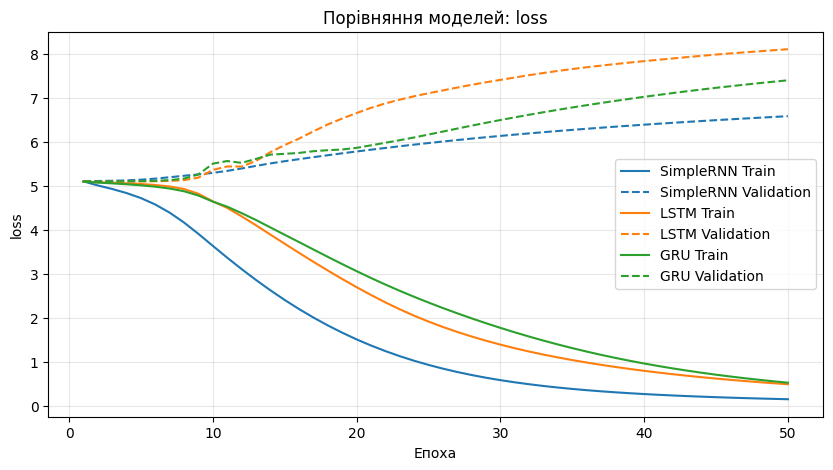

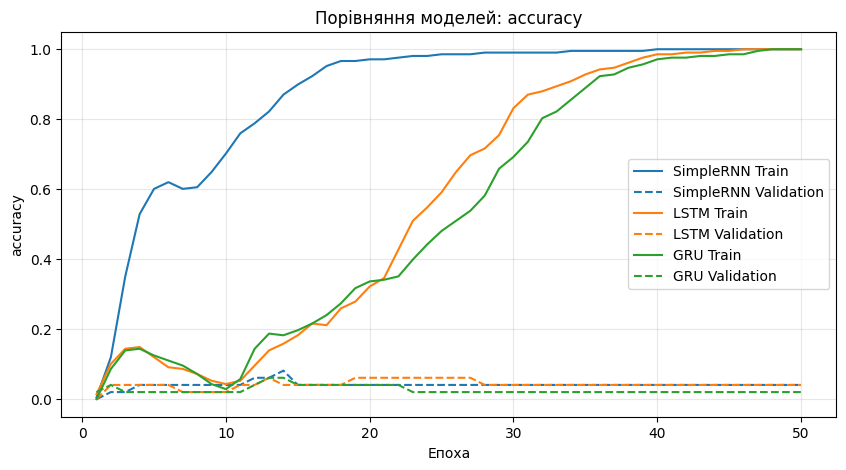

In [11]:
for metric in ['loss', 'accuracy']:
    plt.figure(figsize=(10, 5))
    for name, h in histories5.items():
        line, = plt.plot(range(1, 51), h.history[metric], label=name+' Train')
        plt.plot(range(1, 51), h.history['val_'+metric], '--', color=line.get_color(), label=name+' Validation')
    plt.xlabel('Епоха')
    plt.ylabel(metric)
    plt.title('Порівняння моделей: '+metric)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

### 5.5. Генерація та порівняння
Реалізуйте функцію генерації. Для кожної моделі згенеруйте по 20 слів із двох початкових фраз довжиною не менше п’яти слів. Сформуйте таблицю порівняння моделей.

In [12]:
def generate5(text, model, count=20):
    seq = tok5.texts_to_sequences([text])[0]
    if len(seq) < 5:
        raise ValueError('Потрібно щонайменше 5 слів')
    result = text.split()
    for _ in range(count):
        pred = model(np.array([seq[-5:]], dtype=np.int32), training=False).numpy()[0].copy()
        pred[0] = -1
        pred[tok5.word_index[tok5.oov_token]] = -1
        idx = int(np.argmax(pred))
        seq.append(idx)
        result.append(tok5.index_word[idx])
    return ' '.join(result)
phrases5 = ['Сучасні комп’ютерні технології допомагають людям'.replace('’', "'"), 'Рекурентні нейронні мережі працюють із']
for name, m in models5.items():
    print('\n', name)
    for phrase in phrases5:
        print(generate5(phrase, m))
import pandas as pd
results5 = pd.DataFrame([{'Модель': name, 'Параметри': models5[name].count_params(), 'Train loss': h.history['loss'][-1], 'Train accuracy': h.history['accuracy'][-1], 'Validation loss': h.history['val_loss'][-1], 'Validation accuracy': h.history['val_accuracy'][-1]} for name,h in histories5.items()])
display(results5)


 SimpleRNN
Сучасні комп'ютерні технології допомагають людям навчатися та працювати кожен комп'ютер виконує команди за допомогою програм програми дозволяють обробляти інформацію та розв'язувати складні задачі для створення
Рекурентні нейронні мережі працюють із послідовностями даних кожне слово тексту можна представити числовим індексом модель отримує декілька попередніх слів та прогнозує наступне слово для обробки

 LSTM
Сучасні комп'ютерні технології допомагають людям навчатися та працювати кожен комп'ютер виконує команди за допомогою програм програми дозволяють обробляти інформацію та розв'язувати складні задачі для створення
Рекурентні нейронні мережі працюють із послідовностями даних кожне слово тексту можна представити числовим індексом модель отримує декілька попередніх слів та прогнозує наступне слово для обробки

 GRU
Сучасні комп'ютерні технології допомагають людям навчатися та працювати кожен комп'ютер виконує команди за допомогою програм програми дозволяють обробляти інформ

,Модель,Параметри,Train loss,Train accuracy,Validation loss,Validation accuracy
0,SimpleRNN,43811,0.160319,1.0,6.580832,0.040816
1,LSTM,80867,0.500519,1.0,8.099622,0.040816
2,GRU,68707,0.535253,1.0,7.394366,0.020408


### 5.6. Висновки
У клітинці нижче напишіть 5–7 речень: яка модель показала кращий результат, чи спостерігається перенавчання, як довжина вікна та обсяг корпусу впливають на генерацію. Обґрунтуйте висновки графіками та прикладами.

Для прогнозування наступного слова побудовано три моделі з однаковою розмірністю Embedding 128 та 64 рекурентними нейронами. Найкращу модель визначаємо за валідаційною точністю та втратами після виконання навчання. Якщо навчальні втрати зменшуються, а валідаційні зростають, це свідчить про перенавчання. Вікно з п'яти слів дозволяє врахувати ширший контекст, хоча його перевагу над іншими розмірами потрібно перевіряти окремим експериментом. Невеликий корпус обмежує словник і може спричиняти повторення під час генерації.

Найкраща за валідаційною точністю модель: SimpleRNN (4.08%).

SimpleRNN : є ознаки перенавчання.

LSTM : є ознаки перенавчання.

GRU : є ознаки перенавчання.